In [2]:
# !uv pip install -q "git+https://github.com/kpihx/lab.git"
!uv pip install -P 'kpihx-lab' 'kpihx-lab'

from lab.kit import Context, Runtime

Context.display()

Using Python 3.12.12 environment at: /home/kpihx/Labs/Explore/lab/.venv
Resolved 86 packages in 2.00s                                        
Audited 86 packages in 0.59ms

  πππ    πππ               πππ    πππ   OS      : Linux 7.0.0-34-generic (x86_64)
  πππ  ππππ    KπX-Labs     πππ  πππ   Host    : KpihX-Ubuntu
  πππ πππ    ππππππππππππ    ππππππ   Runtime : local
  ππππππ       πππ  πππ       ππππ   Python  : 3.12.12 @ /home/kpihx/Labs/Explore/lab/.venv/bin/python
  πππππππ      πππ  πππ      πππππ   Base    : /home/kpihx/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu
  πππ  πππ     πππ  πππ      ππππππ   Root    : /home/kpihx/Labs/Explore/lab
  πππ   ππππ   πππ  πππ     πππ  πππ   Device  : Intel XPU (Intel(R) Arc(TM) Graphics)
  πππ    ππππ πππ    ππππ  πππ    πππ   



In [3]:
import kagglehub
import pickle
import numpy as np
from pathlib import Path

dataset_dir = Path(kagglehub.dataset_download("pankrzysiu/cifar10-python")) / "cifar-10-batches-py"

with open(dataset_dir / "batches.meta", "rb") as f:
    classes = [str(c) for c in pickle.load(f, encoding="latin1")["label_names"]]

x_train_list, y_train_list = [], []
for i in range(1, 6):
    with open(dataset_dir / f"data_batch_{i}", "rb") as f:
        batch = pickle.load(f, encoding="latin1")
        x_train_list.append(batch["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1))
        y_train_list.append(batch["labels"])

x_train = np.concatenate(x_train_list, axis=0)
y_train = np.concatenate(y_train_list, axis=0).astype(np.int64)

with open(dataset_dir / "test_batch", "rb") as f:
    test_batch = pickle.load(f, encoding="latin1")
    x_test = test_batch["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y_test = np.array(test_batch["labels"], dtype=np.int64)

print("x_train:", x_train.shape, x_train.dtype)
print("x_test :", x_test.shape, x_test.dtype)
print("classes:", classes)
print("train counts:", np.bincount(y_train))
print("test counts :", np.bincount(y_test))

/home/kpihx/Labs/Explore/lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


x_train: (50000, 32, 32, 3) uint8
x_test : (10000, 32, 32, 3) uint8
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
test counts : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


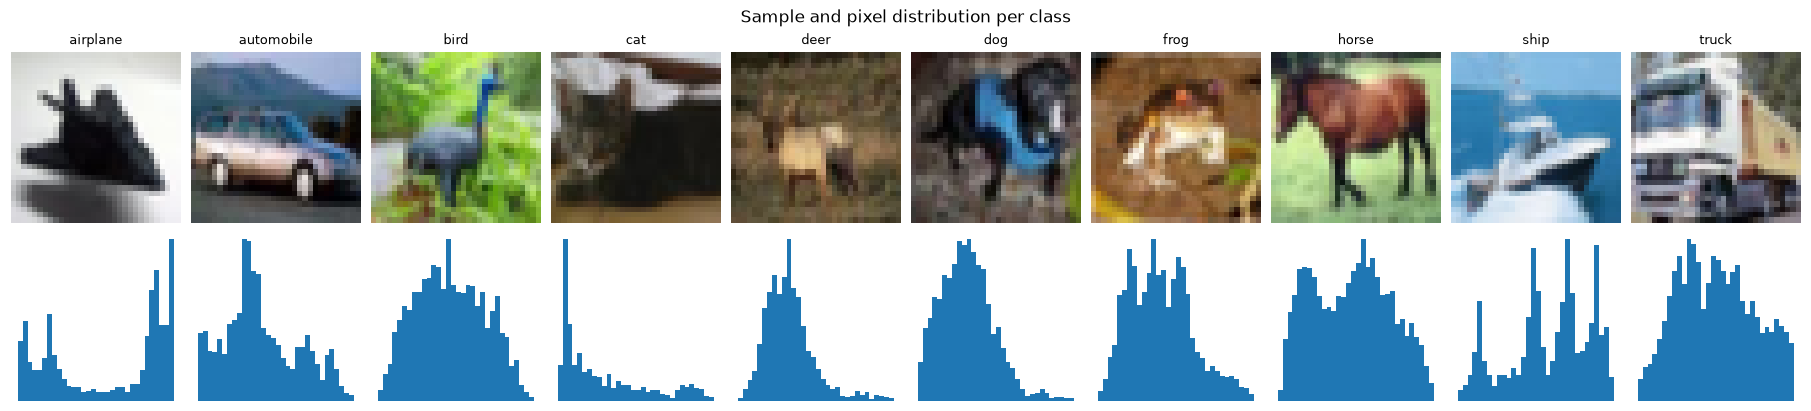

mean: [0.4914 0.4822 0.4465]
std : [0.247  0.2435 0.2616]


In [4]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 10, figsize=(18, 4), constrained_layout=True)
for k, name in enumerate(classes):
    idx = int(np.flatnonzero(y_train == k)[0])
    axs[0, k].imshow(x_train[idx], interpolation="nearest")
    axs[0, k].set_title(name, fontsize=9)
    axs[1, k].hist(x_train[idx].ravel(), bins=32, color="tab:blue")
    axs[0, k].axis("off")
    axs[1, k].axis("off")
plt.suptitle("Sample and pixel distribution per class")
plt.show()


In [ ]:
import torch

if hasattr(torch, "xpu") and torch.xpu.is_available():
    device = "xpu"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

print(device)

x_train_t = torch.from_numpy(x_train).permute(0, 3, 1, 2).to(device)
y_train_t = torch.from_numpy(y_train).to(device)
x_test_t = torch.from_numpy(x_test).permute(0, 3, 1, 2).to(device)
y_test_t = torch.from_numpy(y_test).to(device)

scaled = x_train_t.float().div(255)
mean_t = scaled.mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
std_t = scaled.std(dim=(0, 2, 3), unbiased=False).view(1, 3, 1, 1)
print("mean:", mean_t.flatten().tolist())
print("std :", std_t.flatten().tolist())

from torchvision.transforms import v2

normalize = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=mean_t.flatten().tolist(), std=std_t.flatten().tolist()),
])

augment = v2.Compose([
    v2.RandomCrop(32, padding=4, padding_mode="reflect"),
    v2.RandomHorizontalFlip(),
    v2.RandomErasing(p=0.5),
])

# normalize is deterministic, so it runs once and the tensors it returns
# are the only form the model ever sees. augment stays a function: it draws
# fresh randomness at every call, so materialising x_train_a once would
# freeze one perturbation per image and kill the augmentation.
x_train_n = normalize(x_train_t)
x_test_n = normalize(x_test_t)
del scaled
print("x_train_n:", tuple(x_train_n.shape), x_train_n.dtype)
print("x_test_n :", tuple(x_test_n.shape), x_test_n.dtype)

In [ ]:
generator = torch.Generator().manual_seed(0)
single = x_train_n[0:1]

steps = [
    ("RandomCrop", v2.RandomCrop(32, padding=4, padding_mode="reflect")),
    ("HFlip", v2.RandomHorizontalFlip()),
    ("RandomErasing", v2.RandomErasing(p=0.5)),
    ("augment (all)", augment),
]
draws = 5

fig, axs = plt.subplots(len(steps) + 1, draws + 1, figsize=(2.4 * (draws + 1), 2.4 * (len(steps) + 1)), constrained_layout=True)
for col in range(draws + 1):
    axs[0, col].imshow(single[0].permute(1, 2, 0).clamp(-2, 3).add(2).div(4).cpu().numpy())
axs[0, 0].set_ylabel("original", fontsize=9)

for row, (label, transform) in enumerate(steps, start=1):
    for col in range(draws):
        out = transform(single, generator=generator)
        axs[row, col].imshow(out[0].permute(1, 2, 0).clamp(-2, 3).add(2).div(4).cpu().numpy())
    axs[row, 0].set_ylabel(label, fontsize=9)

for row, (label, _) in enumerate(steps, start=1):
    axs[row, draws].axis("off")
    axs[row, draws].set_ylabel(label, fontsize=9)
for ax in axs.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
axs[0, 1].set_title(f"{draws} draws of each transform (seed 0)", fontsize=10)
plt.show()

In [ ]:
import torch.nn as nn

class PlainCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(True)
        )
        self.body = nn.Sequential(
            nn.Conv2d(32, 32, 3, 1, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.Conv2d(64, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, 1, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.Conv2d(128, 128, 3, 1, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.head(self.body(self.stem(x)))

In [ ]:
import torch.nn.functional as F

class Block(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.short = nn.Sequential()
        # necessary to scale x to the same dim after the output to be able to compute x + f(x)
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(
                nn.Conv2d(cin, cout, 1, stride, bias=False),
                nn.BatchNorm2d(cout)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), True)
        return F.relu(self.bn2(self.conv2(out)) + self.short(x), True)

class ResNet20(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, 1, 1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(True)
        )
        layers, cin = [], 16
        for cout, stride in ((16, 1), (32, 2), (64, 2)):
            for k in range(3):
                layers.append(Block(cin, cout, stride if k == 0 else 1))
                cin = cout
        self.body = nn.Sequential(*layers)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.head(self.body(self.stem(x)))

In [ ]:
plain_model = PlainCNN().to(device)
resnet_model = ResNet20().to(device)

p_params = sum(p.numel() for p in plain_model.parameters() if p.requires_grad)
r_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)

print(f"PlainCNN : {p_params:>8,} parameters")
print(f"ResNet20 : {r_params:>8,} parameters")

In [ ]:
@torch.no_grad()
def evaluate(model, x_n, y):
    model.eval()
    correct = 0
    for i in range(0, len(x_n), 512):
        logits = model(x_n[i:i + 512])
        correct += (logits.argmax(1) == y[i:i + 512]).sum().item()
    return correct / len(x_n)

In [ ]:
epochs = 200
batch_size = 128
lr = 0.1
weight_decay = 5e-4
eval_every = 10

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def train(model):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay, nesterov=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    hist = {"loss": [], "train": [], "test_epoch": [], "test": []}
    
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(x_train_t), device=device)
        total_loss = 0.0
        correct = 0
        for i in range(0, len(x_train_t), batch_size):
            idx = order[i:i + batch_size]
            logits = model(augment(x_train_n[idx]))
            loss = criterion(logits, y_train_t[idx])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(idx)
            correct += (logits.argmax(1) == y_train_t[idx]).sum().item()
        scheduler.step()
        
        hist["loss"].append(total_loss / len(x_train_t))
        hist["train"].append(correct / len(x_train_t))
        if epoch % eval_every == 0 or epoch == epochs:
            acc = evaluate(model, x_test_n, y_test_t)
            hist["test_epoch"].append(epoch)
            hist["test"].append(acc)
            print(f"  epoch {epoch:3d}/{epochs} | loss: {hist['loss'][-1]:.4f} | train: {hist['train'][-1]:.4f} | test: {acc:.4f}")
    return hist

In [ ]:
import time

models = {"PlainCNN": plain_model, "ResNet20": resnet_model}
hists = {}

for name, model in models.items():
    print(f"=== Training {name} ===")
    t0 = time.time()
    hists[name] = train(model)
    print(f"{name} completed in {time.time() - t0:.1f}s")

models = {k: v.eval() for k, v in models.items()}

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for name, h in hists.items():
    axs[0].plot(h["loss"], label=name)
    axs[1].plot(h["train"], label=name)
    axs[2].plot(h["test_epoch"], h["test"], marker="o", label=name)

for ax, t in zip(axs, ("Loss", "Train accuracy", "Test accuracy")):
    ax.set(title=t, xlabel="Epoch", ylabel=t)
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

In [ ]:
from lab import class_eval

for name, model in models.items():
    with torch.no_grad():
        probas = torch.cat([
            model(x_test_n[i:i + 512]).softmax(1)
            for i in range(0, len(x_test_n), 512)
        ]).cpu().numpy()
    print(f"=== {name} ===")
    class_eval(y_test, probas.argmax(1), probas, classes=classes)

In [ ]:
for name, model in models.items():
    w = model.stem[0].weight.detach().cpu()
    n_filters = w.shape[0]
    cols = 8
    rows = int(np.ceil(n_filters / cols))
    fig, axs = plt.subplots(rows, cols * 3, figsize=(cols * 2.8, rows * 1.3), constrained_layout=True)
    for k in range(rows * cols * 3):
        r, c = divmod(k, cols * 3)
        filt_idx = r * cols + c // 3
        ch_idx = c % 3
        if filt_idx < n_filters:
            axs[r, c].imshow(w[filt_idx, ch_idx], cmap="bwr", vmin=-w.abs().max(), vmax=w.abs().max())
            if ch_idx == 0:
                axs[r, c].set_title(f"k{filt_idx}", fontsize=7)
        axs[r, c].axis("off")
    plt.suptitle(f"{name} - First layer filters (RGB components)")
    plt.show()

In [ ]:
picks = [int(np.flatnonzero(y_test == c)[0]) for c in (0, 3, 5, 7)]
probe = x_test_n[picks[0]:picks[0] + 1]

for name, model in models.items():
    feat_store = {}
    hook = model.body.register_forward_hook(lambda m, i, o: feat_store.__setitem__("feat", o.detach()))
    with torch.no_grad():
        model(probe)
    hook.remove()
    f = feat_store["feat"][0]
    top = f.abs().flatten(1).mean(1).argsort(descending=True)[:8]
    fig, axs = plt.subplots(1, 8, figsize=(16, 2.2), constrained_layout=True)
    for ax, ch in zip(axs, top):
        ax.imshow(f[ch].cpu(), cmap="viridis", interpolation="nearest")
        ax.set_title(f"ch {int(ch)}", fontsize=8)
        ax.axis("off")
    plt.suptitle(f"{name} - 8 most active feature maps ({classes[y_test[picks[0]]]})", fontsize=10)
    plt.show()

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.act = None
        self.grad = None
        self.hook = layer.register_forward_hook(self._fwd)

    def _fwd(self, m, i, o):
        self.act = o
        if o.requires_grad:
            o.register_hook(self._grad)

    def _grad(self, g):
        self.grad = g

    def __call__(self, x):
        logits = self.model(x)
        self.model.zero_grad(set_to_none=True)
        logits.sum().backward()
        cam = (self.grad.mean((2, 3), keepdim=True) * self.act).sum(1, keepdim=True).relu()
        cam = F.interpolate(cam, x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        low = cam.amin((1, 2), keepdim=True)
        high = cam.amax((1, 2), keepdim=True)
        return ((cam - low) / (high - low + 1e-8)).detach().cpu().numpy()

    def remove(self):
        self.hook.remove()

for name, model in models.items():
    gcam = GradCAM(model, model.body)
    probe_batch = x_test_n[picks]
    with torch.enable_grad():
        heat = gcam(probe_batch)
    gcam.remove()
    
    fig, axs = plt.subplots(2, len(picks), figsize=(11, 4.5), constrained_layout=True)
    for k, i in enumerate(picks):
        raw_img = x_test[i]
        axs[0, k].imshow(raw_img, interpolation="nearest")
        axs[0, k].set_title(classes[y_test[i]], fontsize=9)
        axs[1, k].imshow(raw_img, interpolation="nearest")
        axs[1, k].imshow(heat[k], cmap="jet", alpha=0.5, interpolation="bilinear")
        axs[0, k].axis("off")
        axs[1, k].axis("off")
    plt.suptitle(f"{name} - Grad-CAM saliency maps", fontsize=11)
    plt.show()

In [ ]:
shifts = [(-4, 0), (4, 0), (0, -4), (0, 4), (-4, -4), (4, 4)]

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
for name, model in models.items():
    base = evaluate(model, x_test_n, y_test_t)
    drops = [base - evaluate(model, torch.roll(x_test_n, shifts=s, dims=(2, 3)), y_test_t) for s in shifts]
    print(f"{name:9s} base: {base:.4f} | max drop: {max(drops):.4f}")
    ax.plot([f"{a:+d},{b:+d}" for a, b in shifts], drops, marker="o", label=name)

ax.set(title="Accuracy drop under spatial translations", ylabel="Accuracy Drop")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [ ]:
for name, model in models.items():
    out_path = Context.resolve(Path(f"assets/outputs/{name.lower()}_cifar10.pt"))
    out_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), out_path)
    print("saved:", out_path)